In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import nltk 
from sklearn.model_selection import train_test_split

In [15]:
dataset = pd.read_csv("spamdataset.csv", encoding='latin-1')
dataset.head(3)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN


In [16]:
dataset = dataset.loc[:, ~dataset.columns.str.contains("^Unnamed")]

In [4]:
dataset.head(3)

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...


In [5]:
dataset.isnull().sum()

v1    0
v2    0
dtype: int64

In [6]:
dataset.describe()

,v1,v2
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [7]:
dataset = dataset.rename(columns={
    "v1": "label",
    "v2": "message"
})


In [8]:
# Standardize labels and text
dataset["label"] = dataset["label"].str.strip().str.lower()
dataset["message"] = dataset["message"].astype(str)

In [9]:
import re
def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


dataset["clean_message"] = dataset["message"].apply(preprocess_text)

display(dataset[["message", "clean_message"]].head())


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [10]:

X = dataset["clean_message"]
y = dataset["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Model 1: Multinomial Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", MultinomialNB())
])
nb_model.fit(X_train, y_train)

# Model 2: Logistic Regression
lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000))
])
lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


models = {
    "Multinomial Naive Bayes": nb_model,
    "Logistic Regression": lr_model
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="spam", zero_division=0
        )
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Multinomial Naive Bayes,0.9668,0.9912,0.7584,0.8593
Logistic Regression,0.9668,1.0000,0.7517,0.8582



Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       0.99      0.76      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



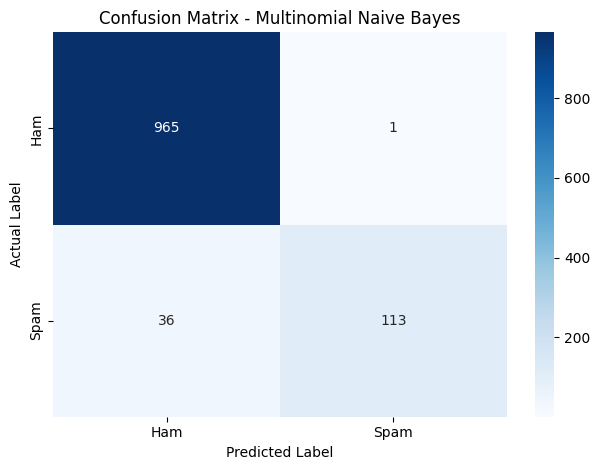


Logistic Regression
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.75      0.86       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



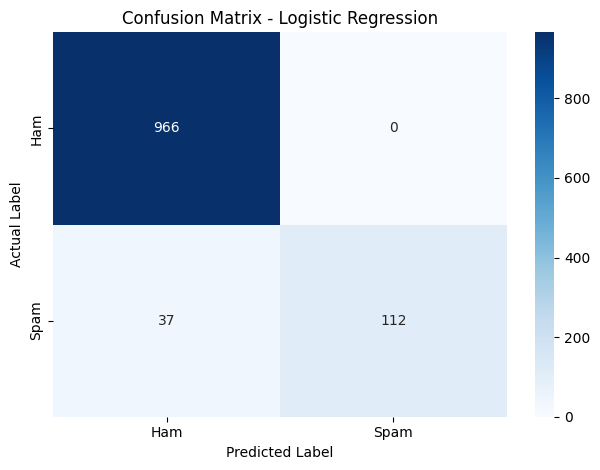

In [13]:

for name, model in models.items():
    y_pred = model.predict(X_test)

    print(f"\n{'=' * 50}")
    print(name)
    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["ham", "spam"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()


In [18]:

## Why Is Recall Particularly Important for Spam Detection?

Recall measures the proportion of actual spam messages correctly identified by the model.

Recall = True Positives / (True Positives + False Negatives)
However, precision is also important. Low precision means legitimate messages may be incorrectly marked as spam.

A good spam detection model should balance recall and precision while maintaining a strong F1-score.


SyntaxError: invalid syntax (4095132306.py, line 3)